# Exemplar events

In [34]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.gridspec as gridspec
import cartopy.crs as ccrs, cartopy.feature as cfeature
from matplotlib.patches import Rectangle, Patch
from matplotlib.collections import PatchCollection
from matplotlib.lines import Line2D
from pathlib import Path

In [35]:
YEAR = 2025 # 2024 or 2025
MIN_CELLS = 10     #shows events with at least this many grid cells

TIME, WINDOW_DAYS = "datetime_local", 7   # windows are ±7 days around each cell's own pulse onset
BASE = "/global/scratch/users/rubypercival/0.1x0.1_deg_gridded_datasets/" + ("final_datasets_excl")
FIGDIR = Path("/global/scratch/users/rubypercival/figures"); FIGDIR.mkdir(parents=True, exist_ok=True)
groups_df = pd.read_parquet(f"{BASE}/lowCF_grouped_2hour_pulses_MCD12Q1mask_{YEAR}_post10am.parquet")
df = pd.read_parquet(f"{BASE}/lowCF_filtered_merged_with_incdec_MCD12Q1mask_{YEAR}.parquet",
                     columns=["grid_lat", "grid_lon", TIME, "h_precip_mm", "no2_mean", "WFPS_c"])
groups_df[TIME] = pd.to_datetime(groups_df[TIME]); df[TIME] = pd.to_datetime(df[TIME])

In [36]:
def event_daily(eids):
    ep = groups_df[groups_df["group_id"].isin(eids)]
    ref = ep.groupby(["group_id", "grid_lat", "grid_lon"])[TIME].min().rename("t_ref").reset_index()
    sub = df.merge(ref, on=["grid_lat", "grid_lon"])
    dt = (sub[TIME] - sub["t_ref"]).dt.total_seconds() / 86400
    sub = sub[dt.abs() <= WINDOW_DAYS].assign(lag_day=np.floor(dt).astype(int))
    cd = sub.groupby(["group_id", "grid_lat", "grid_lon", "lag_day"]).agg(
        precip=("h_precip_mm", "sum"), no2=("no2_mean", "mean"), wfps=("WFPS_c", "mean")).reset_index()
    
  
    w0 = cd.loc[cd.lag_day.eq(0), ["group_id", "grid_lat", "grid_lon", "wfps"]].rename(columns={"wfps": "wfps0"})
    cd = cd.merge(w0, on=["group_id", "grid_lat", "grid_lon"], how="left")
    cd["wfps_anom"] = cd["wfps"] - cd["wfps0"]
    out = {}
    for eid, g in cd.groupby("group_id"):
        d = g.groupby("lag_day").agg(precip_mean=("precip", "mean"), no2_mean=("no2", "mean"), no2_std=("no2", "std"),
                                     wfps_mean=("wfps", "mean"), wfps_band=("wfps_anom", "std"))
        d = d.reindex(np.arange(-WINDOW_DAYS, WINDOW_DAYS + 1))
        d["precip_mean"] = d["precip_mean"].fillna(0)
        p = ep[ep.group_id.eq(eid)]
        dw = g.pivot_table(index=["grid_lat", "grid_lon"], columns="lag_day", values="wfps")
        out[eid] = dict(pulses=p, cells=p[["grid_lat", "grid_lon"]].drop_duplicates(), daily=d, t0=p[TIME].min(),
                        dwfps=(dw.get(0) - dw.get(-5)).mean() if {0, -5} <= set(dw.columns) else np.nan)
    return out

def plot_ts(ax, d, lw=1.0, ms=2.0, no2_offset=24):
    x = d.index
    ax.bar(x, d.precip_mean, color="steelblue", alpha=0.35, width=0.8, zorder=2)
    ax.axvline(0, color="black", ls="--", lw=0.7, alpha=0.7, zorder=3)
    ax.set_xlim(-WINDOW_DAYS - 0.5, WINDOW_DAYS + 0.5); ax.set_xticks(np.arange(-WINDOW_DAYS, WINDOW_DAYS + 1, 2))
    aw, an = ax.twinx(), ax.twinx()
    an.spines["right"].set_position(("outward", no2_offset))
    v = d.wfps_mean.notna()
    aw.plot(x[v], d.wfps_mean[v], color="olivedrab", lw=lw, marker="o", ms=ms, zorder=4)
    aw.fill_between(x[v], (d.wfps_mean - d.wfps_band)[v], (d.wfps_mean + d.wfps_band)[v], color="#70AD47", alpha=0.12)
    v = d.no2_mean.notna()
    an.plot(x[v], d.no2_mean[v], color="coral", ls="--", lw=lw, marker="s", ms=ms, zorder=5)
    an.fill_between(x[v], (d.no2_mean - d.no2_std)[v], (d.no2_mean + d.no2_std)[v], color="#ED7D31", alpha=0.12)
    for a, c in [(ax, "steelblue"), (aw, "olivedrab"), (an, "coral")]:
        a.tick_params(axis="y", labelcolor=c); a.spines[["top"]].set_visible(False)
    return aw, an

## All candidate events

In [37]:
first = groups_df.sort_values(TIME).drop_duplicates(["group_id", "grid_lat", "grid_lon"])
cand = first.groupby("group_id").agg(n_cells=("sm_class", "size"), frac_inc=("sm_class", lambda s: s.eq("increasing").mean()),
                                     start=(TIME, "min"), spread_h=(TIME, lambda t: (t.max() - t.min()).total_seconds() / 3600))
for c in ["state_name", "dominant_texture"]:
    if c in first.columns:
        cand[c] = first.groupby("group_id")[c].agg(lambda s: s.mode().iat[0] if s.notna().any() else None)
cand = cand[cand.n_cells >= MIN_CELLS]
EV = event_daily(cand.index)
cand["dWFPS_5d"] = pd.Series({e: v["dwfps"] for e, v in EV.items()})
cand = cand.sort_values(["frac_inc", "dWFPS_5d"], ascending=False)
cand.round({"frac_inc": 2, "spread_h": 0, "dWFPS_5d": 3})

,n_cells,frac_inc,start,spread_h,state_name,dominant_texture,dWFPS_5d
group_id,,,,,,,
2263,17,1.0,2025-04-21 10:00:00,6.0,Minnesota,clay loam,0.242
3875,70,1.0,2025-05-23 10:00:00,7.0,Indiana,silt loam,0.176
1459,27,1.0,2025-03-31 13:00:00,2.0,Minnesota,silt loam,0.123
1418,22,1.0,2025-03-25 11:00:00,27.0,Illinois,silt loam,0.109
1555,10,1.0,2025-04-07 10:00:00,4.0,Tennessee,silt loam,0.075
...,...,...,...,...,...,...,...
4797,16,0.0,2025-07-04 18:00:00,24.0,Indiana,silty clay loam,-0.186
3353,79,0.0,2025-05-07 13:00:00,4.0,North Dakota,loam,-0.187
4067,10,0.0,2025-05-25 13:00:00,3.0,North Dakota,loam,-0.190


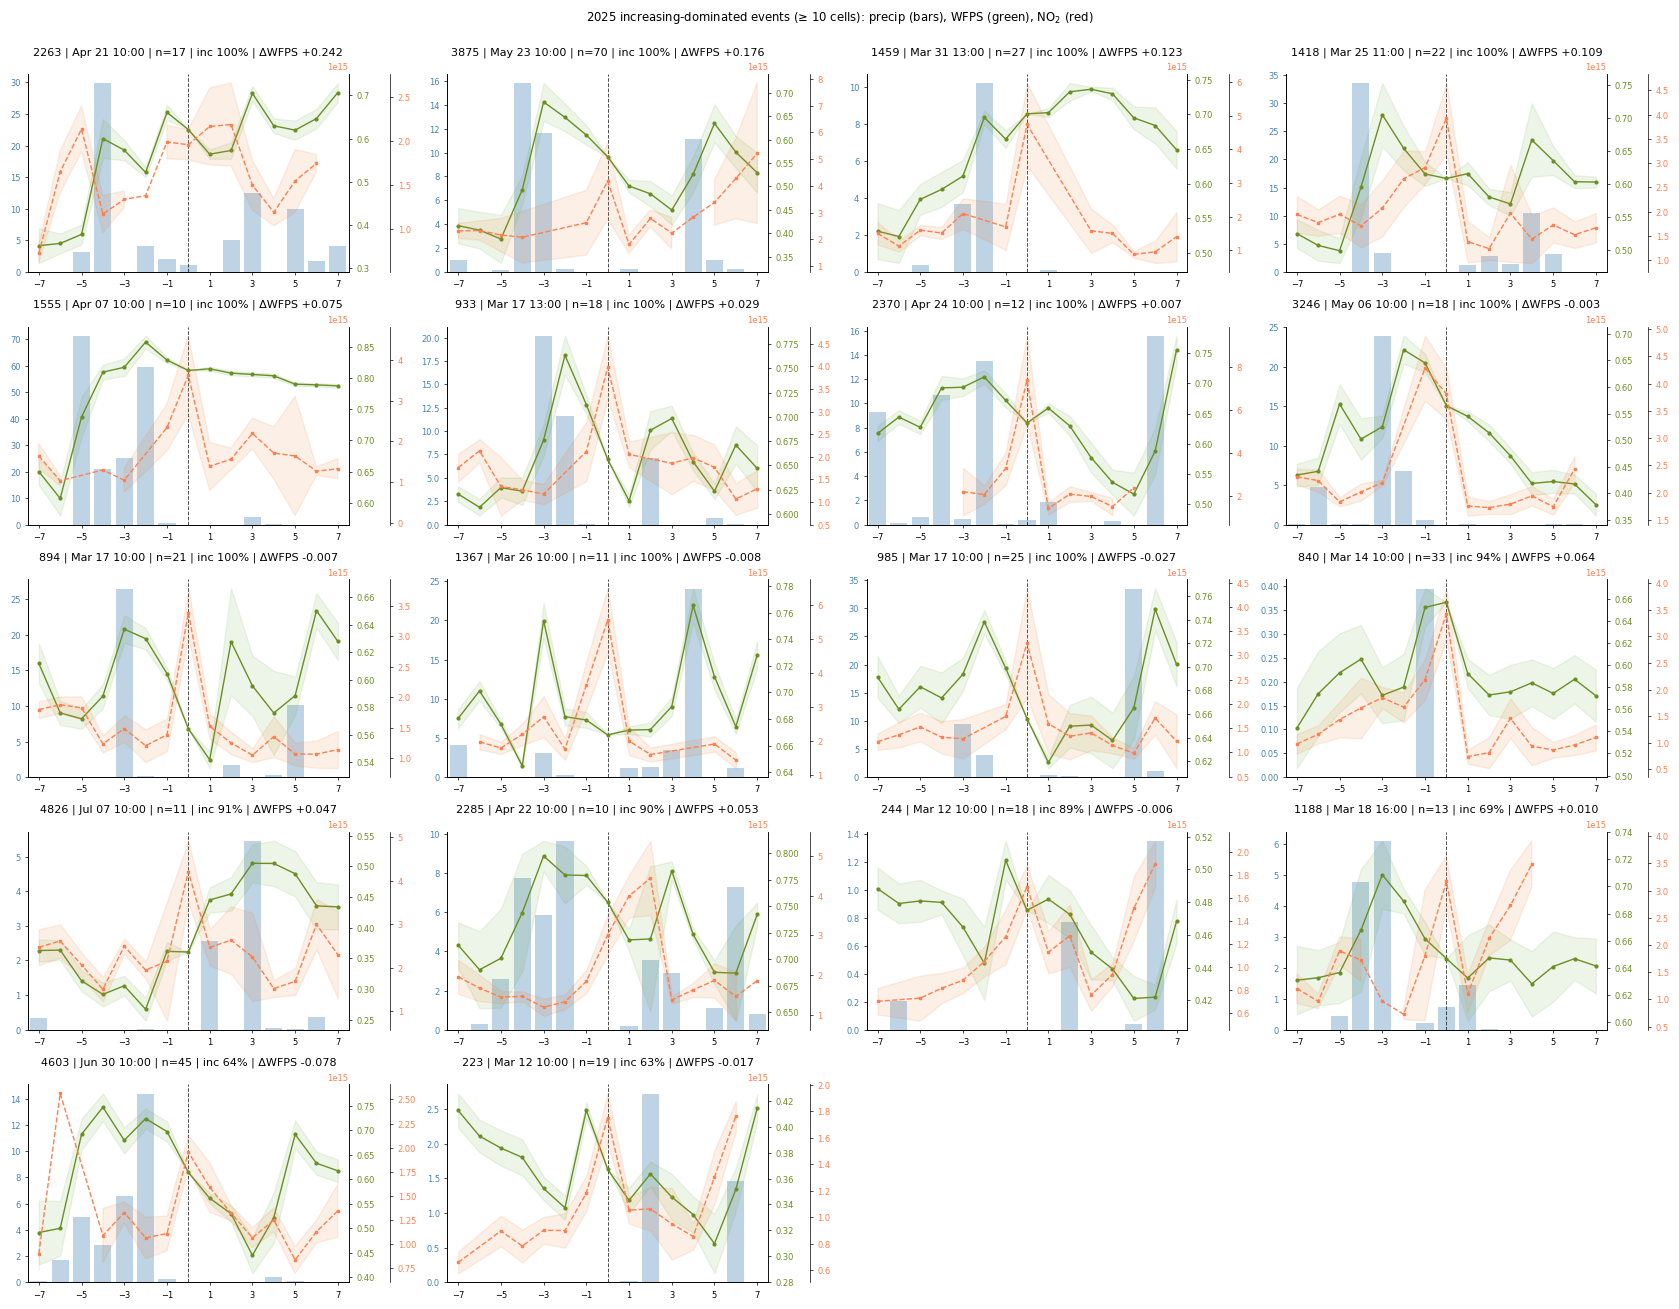

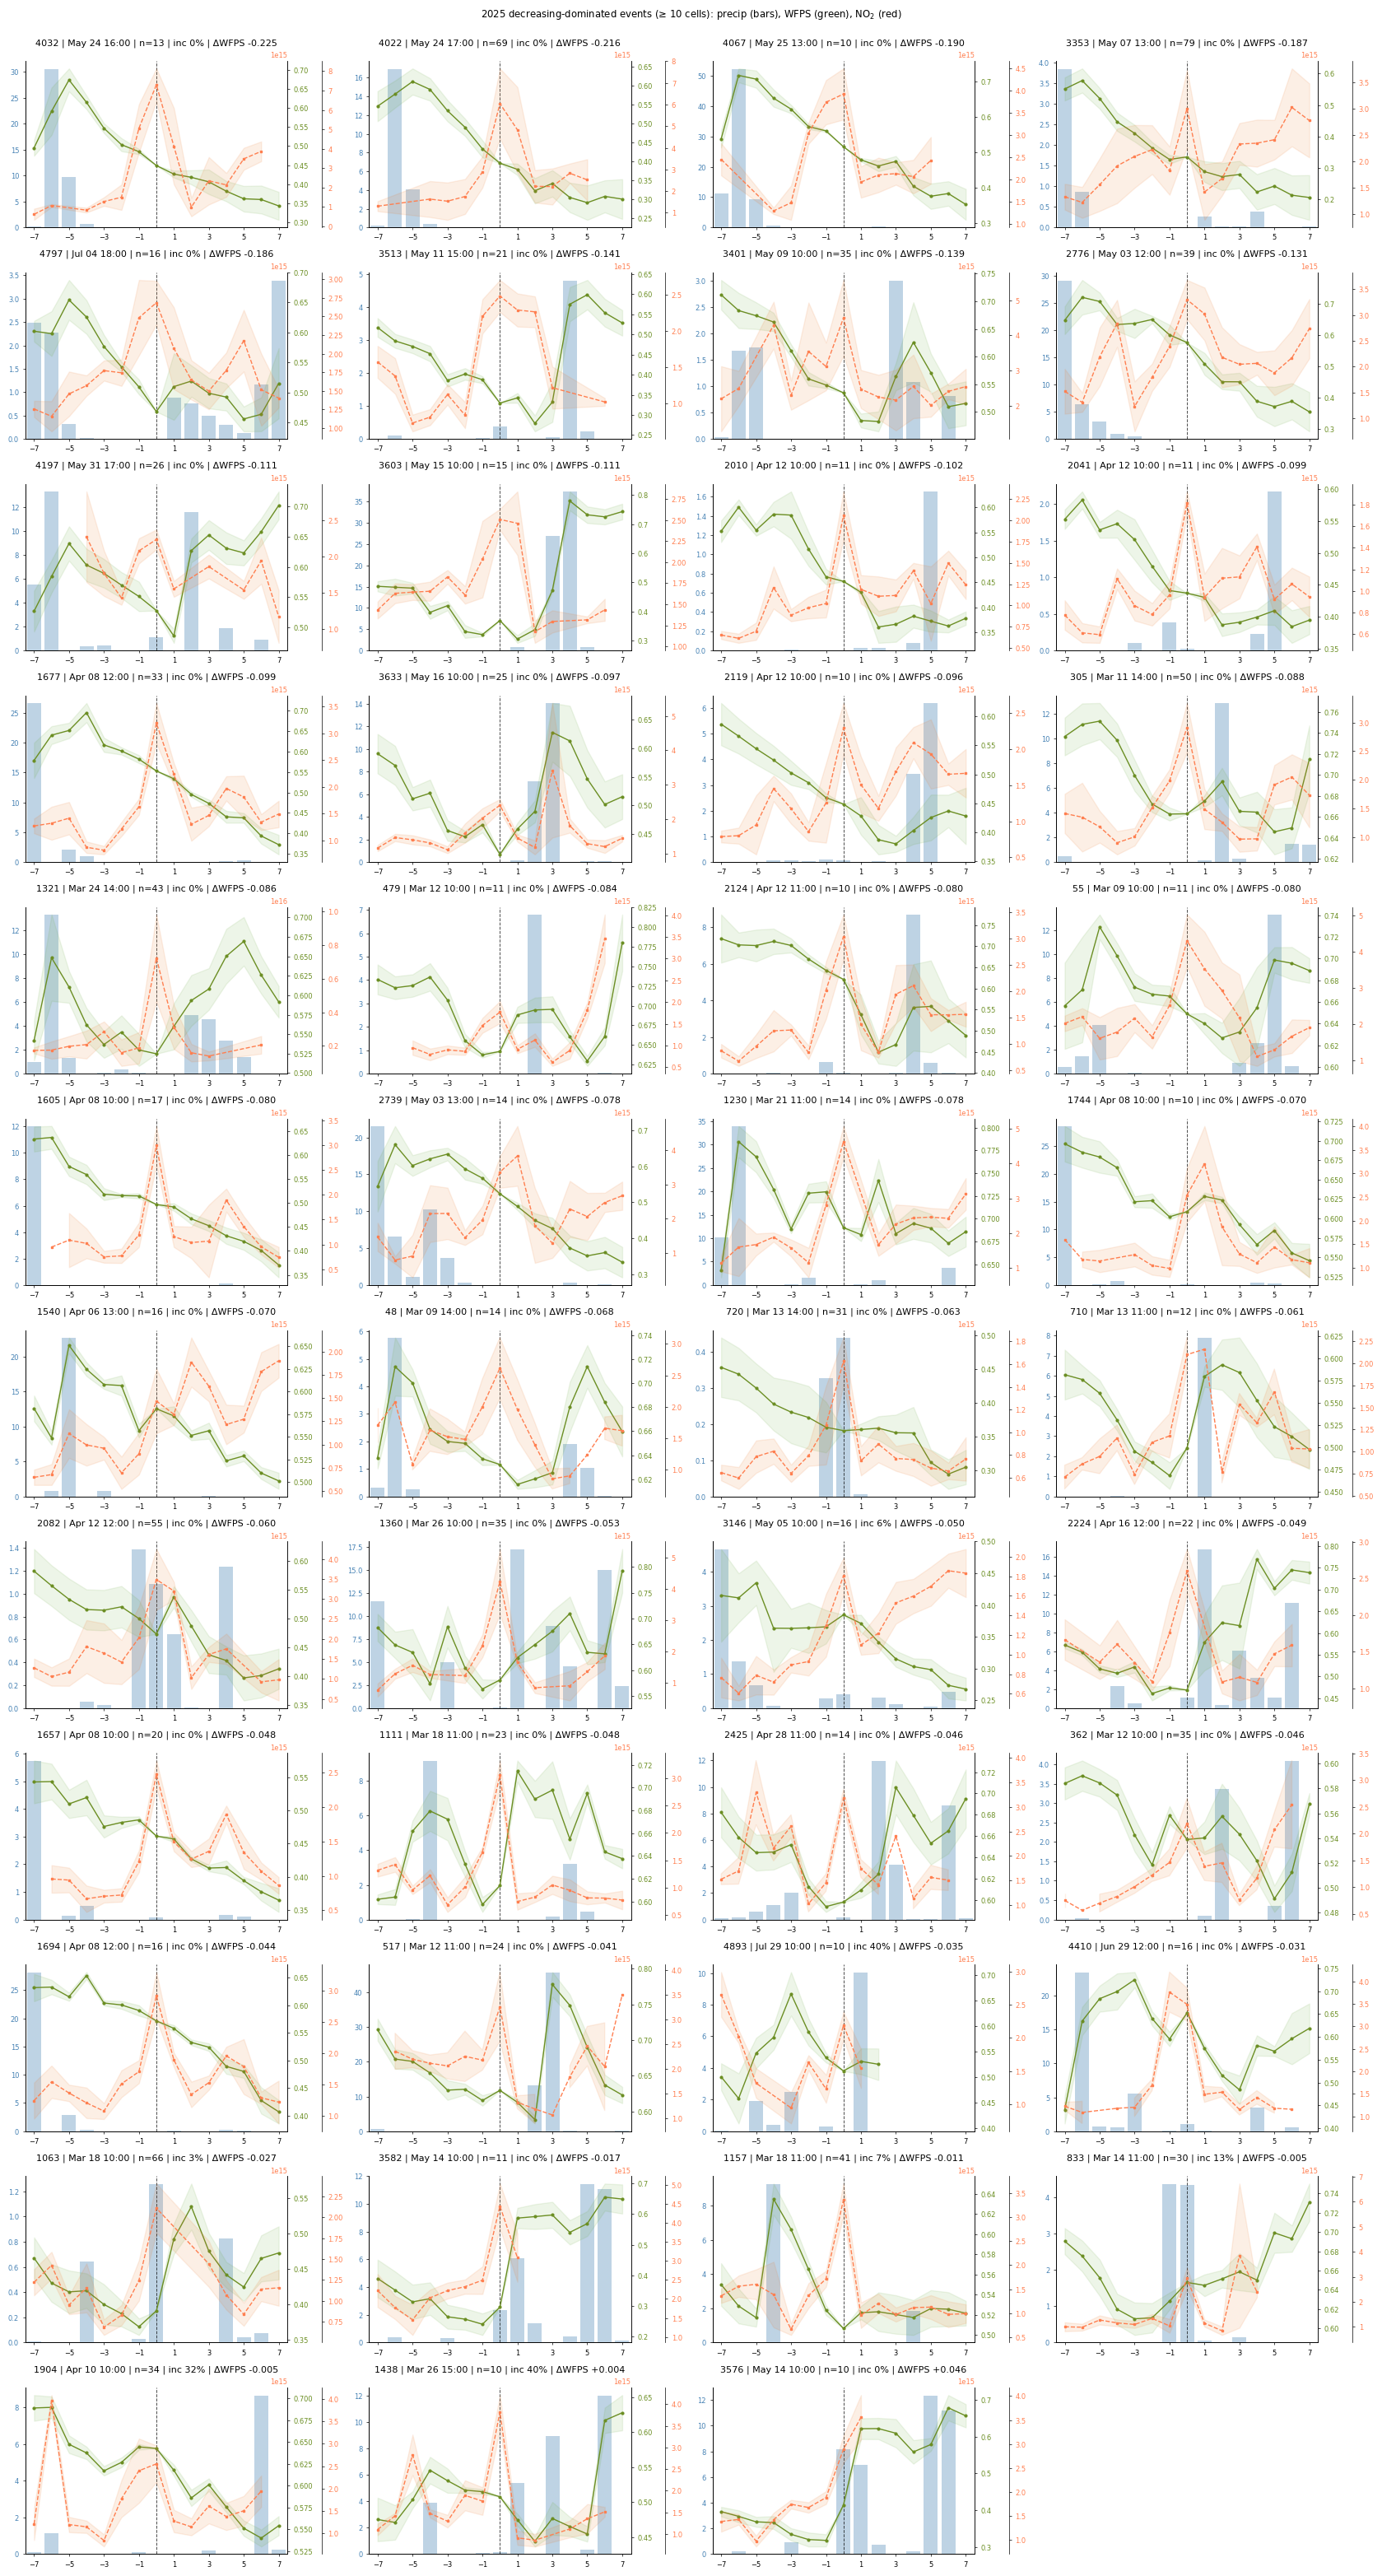

In [38]:
NCOL = 4
for name, ids in [("increasing", cand.index[cand.frac_inc >= 0.5]), ("decreasing", cand[cand.frac_inc < 0.5].sort_values("dWFPS_5d").index)]:
    if not len(ids): continue
    nrow = int(np.ceil(len(ids) / NCOL))
    fig, axs = plt.subplots(nrow, NCOL, figsize=(4.2 * NCOL, 2.6 * nrow), squeeze=False)
    for ax, eid in zip(axs.flat, ids):
        r = cand.loc[eid]
        plot_ts(ax, EV[eid]["daily"], no2_offset=30)
        ax.set_title(f"{eid} | {r.start:%b %d %H:%M} | n={r.n_cells} | inc {r.frac_inc:.0%} | ΔWFPS {r.dWFPS_5d:+.3f}", fontsize=8)
    for ax in axs.flat[len(ids):]: ax.axis("off")
    fig.suptitle(f"{YEAR} {name}-dominated events (≥ {MIN_CELLS} cells): precip (bars), WFPS (green), NO$_2$ (red)", y=1.0)
    fig.tight_layout(); plt.show()

## PNAS figure for chosen events

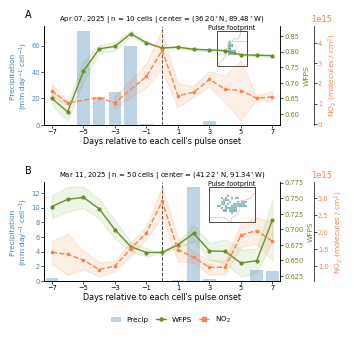

In [47]:
EVENTS = [1555, 305]  
#4826
plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams.update({"font.size": 7, "axes.labelsize": 7, "axes.titlesize": 7, "xtick.labelsize": 6, "ytick.labelsize": 6,
                     "legend.fontsize": 6, "lines.linewidth": 1.0, "axes.linewidth": 0.5, "xtick.major.width": 0.5,
                     "ytick.major.width": 0.5, "xtick.major.size": 2, "ytick.major.size": 2, "pdf.fonttype": 42, "ps.fonttype": 42})

sel = {e: EV[e] if e in EV else event_daily([e])[e] for e in EVENTS}
cm = 1 / 2.54
fig = plt.figure(figsize=(8.7 * cm, 4.15 * cm * len(EVENTS)))
outer = gridspec.GridSpec(len(EVENTS), 1, hspace=0.58, top=0.96, bottom=0.18, left=0.13, right=0.82)
ts_axes = []
for row, eid in enumerate(EVENTS):
    e = sel[eid]; cells = e["cells"]
    ax = fig.add_subplot(outer[row]); ts_axes.append(ax)
    aw, an = plot_ts(ax, e["daily"])
    for a in (ax, aw, an): a.tick_params(labelsize=4.8, pad=1, length=2)
    ax.set_ylabel("Precipitation \n(mm day$^{-1}$ cell$^{-1}$)", color="steelblue", labelpad=1, fontsize=5.3)
    aw.set_ylabel("WFPS", color="olivedrab", labelpad=3, fontsize=5.3)
    an.set_ylabel("NO$_2$ (molecules / cm$^{2}$)", color="coral", labelpad=3, fontsize=5.3)
    an.yaxis.get_offset_text().set(x=1.22, y=1.02, color="coral")
    ax.set_xlabel("Days relative to each cell's pulse onset", fontsize=5.8, labelpad=1)
    ax.set_title(f"{e['t0']:%b %d, %Y} | n = {len(cells)} cells | center = ({cells.grid_lat.mean():.2f}$^\\circ$N, "
                 f"{abs(cells.grid_lon.mean()):.2f}$^\\circ$W)", fontsize=5.0, pad=2)

    m = ax.inset_axes([0.62, 0.60, 0.35, 0.35], projection=ccrs.PlateCarree())
    m.set_extent([cells.grid_lon.min() - 0.45, cells.grid_lon.max() + 0.45, cells.grid_lat.min() - 0.45, cells.grid_lat.max() + 0.45], crs=ccrs.PlateCarree())
    m.add_feature(cfeature.STATES.with_scale("50m"), edgecolor="silver", linewidth=0.25, zorder=2)
    m.add_feature(cfeature.BORDERS.with_scale("50m"), edgecolor="black", linewidth=0.3, zorder=3)
    m.coastlines(resolution="50m", linewidth=0.25, zorder=1)
    pc = PatchCollection([Rectangle((lo - 0.05, la - 0.05), 0.1, 0.1) for lo, la in zip(cells.grid_lon, cells.grid_lat)],
                         facecolor="cadetblue", edgecolor="white", alpha=0.95, linewidth=0.2, zorder= 1, transform=ccrs.PlateCarree())
    m.add_collection(pc); m.set_xticks([]); m.set_yticks([])
    m.set_title("Pulse footprint", fontsize=4.6, pad=1)

fig.canvas.draw()
for ax, lab in zip(ts_axes, "ABCDEFGH"):
    p = ax.get_position(); fig.text(p.x0 - 0.055, p.y1 + 0.05, lab, ha="left", va="top", fontsize=7)
fig.legend(handles=[Patch(facecolor="steelblue", alpha=0.35, label="Precip"),
                    Line2D([0], [0], color="olivedrab", lw=1.0, marker="o", ms=2.2, label="WFPS"),
                    Line2D([0], [0], color="coral", ls="--", lw=1.0, marker="s", ms=2.2, label="NO$_2$")],
           loc="lower center", bbox_to_anchor=(0.5, 0.025), ncol=3, frameon=False, fontsize=5.2, handlelength=1.4, columnspacing=1.0)
fig.savefig(f"4A_4B_exemplars_{YEAR}_{'_'.join(map(str, EVENTS))}.pdf", bbox_inches="tight")
plt.show()